In [1]:
# Put the repository root on sys.path, wherever the kernel was started from.
import os, sys

def _find_repo_root():
    _pkgs = ("genotyping", "pipelines", "screening", "sequencing")
    for _cand in [os.getcwd(), *sys.path]:
        if not _cand:
            continue
        _d = os.path.abspath(_cand)
        while True:
            if all(os.path.isdir(os.path.join(_d, _p)) for _p in _pkgs):
                return _d
            _parent = os.path.dirname(_d)
            if _parent == _d:
                break
            _d = _parent
    return None

_repo_root = _find_repo_root()
if _repo_root and _repo_root not in sys.path:
    sys.path.insert(0, _repo_root)

from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

import A14_02_config as config
from pathlib import Path
import sys
import os
import multiprocessing as mp
import importlib

import pandas as pd
import os
# import seaborn as sns
import matplotlib.pyplot as plt

from pipelines import common_tasks

# Reload the modules
importlib.reload(config)
importlib.reload(common_tasks)

from screening import screen_utils

/mnt/mnemo2/opt/conda/envs/tnpb-analysis/lib/python3.10/site-packages/Bio/pairwise2.py:278: BiopythonDeprecationWarning: Bio.pairwise2 has been deprecated, and we intend to remove it in a future release of Biopython. As an alternative, please consider using Bio.Align.PairwiseAligner as a replacement, and contact the Biopython developers if you still need the Bio.pairwise2 module.
  warnings.warn(


In [2]:
lib=config.get_library()
lib 

,Unnamed: 0,finalname,lib_section,specific_primerpart,barcode,spacer,target rv,oligofinal,llength,barcode_verified,target_site_rc_PlusTAM,target_site_PlusTAM,target_site,TAM
0,NaN,LIB_A14-01,LIB-A14-01,NaN,GCACGTA,TTCCAGTTAAGGAGAGGAAT,ATTCCTCTCCTTAACTGGAAATCTT,CGCGACTTTAGTCGTGTGAGGTTCAATTCCAGTTAAGGAGAGGAAT...,209,GCACGTA,ATTCCTCTCCTTAACTGGAAATCTT,AAGATTTCCAGTTAAGGAGAGGAAT,TTCCAGTTAAGGAGAGGAAT,AAGAT
1,NaN,LIB_A14-01,LIB-A14-01,NaN,CGACGTC,TGAAAACTTCAGTGATATCG,CGATATCACTGAAGTTTTCAATCTT,CGCGACTTTAGTCGTGTGAGGTTCAATGAAAACTTCAGTGATATCG...,209,CGACGTC,CGATATCACTGAAGTTTTCAATCTT,AAGATTGAAAACTTCAGTGATATCG,TGAAAACTTCAGTGATATCG,AAGAT
2,NaN,LIB_A14-01,LIB-A14-01,NaN,GATGTTC,GGCAGAAGGTACACAGCAAC,GTTGCTGTGTACCTTCTGCCATCTT,CGCGACTTTAGTCGTGTGAGGTTCAAGGCAGAAGGTACACAGCAAC...,209,GATGTTC,GTTGCTGTGTACCTTCTGCCATCTT,AAGATGGCAGAAGGTACACAGCAAC,GGCAGAAGGTACACAGCAAC,AAGAT
3,NaN,LIB_A14-01,LIB-A14-01,NaN,AGGAAAT,TATAGTTAAAAATATGCCAC,GTGGCATATTTTTAACTATAATCTT,CGCGACTTTAGTCGTGTGAGGTTCAATATAGTTAAAAATATGCCAC...,209,AGGAAAT,GTGGCATATTTTTAACTATAATCTT,AAGATTATAGTTAAAAATATGCCAC,TATAGTTAAAAATATGCCAC,AAGAT
4,NaN,LIB_A14-01,LIB-A14-01,NaN,GTCGCCT,AAGGAGATTATACCCAGAAT,ATTCTGGGTATAATCTCCTTATCTT,CGCGACTTTAGTCGTGTGAGGTTCAAAAGGAGATTATACCCAGAAT...,209,GTCGCCT,ATTCTGGGTATAATCTCCTTATCTT,AAGATAAGGAGATTATACCCAGAAT,AAGGAGATTATACCCAGAAT,AAGAT
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
479,NaN,LIB_A14-01,LIB-A14-01,NaN,GTGACTT,TTAGGTAAATAAAGATCTCT,AGAGATCTTTATTTACCTAACTCAA,CGCGACTTTAGTCGTGTGAGGTTCAATTAGGTAAATAAAGATCTCT...,209,GTGACTT,AGAGATCTTTATTTACCTAACTCAA,TTGAGTTAGGTAAATAAAGATCTCT,TTAGGTAAATAAAGATCTCT,TTGAG
480,NaN,LIB_A14-01,LIB-A14-01,NaN,TGTCCTA,TTCTACTCAAGCCGCTCTAC,GTAGAGCGGCTTGAGTAGAACTCAA,CGCGACTTTAGTCGTGTGAGGTTCAATTCTACTCAAGCCGCTCTAC...,209,TGTCCTA,GTAGAGCGGCTTGAGTAGAACTCAA,TTGAGTTCTACTCAAGCCGCTCTAC,TTCTACTCAAGCCGCTCTAC,TTGAG
481,NaN,LIB_A14-01,LIB-A14-01,NaN,GCAACCA,GAAGAGGACCTGGGAGATGA,TCATCTCCCAGGTCCTCTTCCTCAA,CGCGACTTTAGTCGTGTGAGGTTCAAGAAGAGGACCTGGGAGATGA...,209,GCAACCA,TCATCTCCCAGGTCCTCTTCCTCAA,TTGAGGAAGAGGACCTGGGAGATGA,GAAGAGGACCTGGGAGATGA,TTGAG
482,NaN,LIB_A14-01,LIB-A14-01,NaN,GGTAACG,TATTATATATGAGTTCACTG,CAGTGAACTCATATATAATACTCAA,CGCGACTTTAGTCGTGTGAGGTTCAATATTATATATGAGTTCACTG...,209,GGTAACG,CAGTGAACTCATATATAATACTCAA,TTGAGTATTATATATGAGTTCACTG,TATTATATATGAGTTCACTG,TTGAG


In [3]:
samples= config.get_samples()
samples 

,sample_name,sequencing_name,bioreplicate,replicate,file_name_R1,file_name_R2,editor,is_ctrl,lib_section
0,A14-02_Sample-1_TnpB-WT_ABE_LIB-A14-01_rep1,Sample-1,TnpB-WT_ABE_LIB-A14-01,1,Sample_1_MKDL260000002-1A_237LJ3LT4_L4_1.fq.gz,Sample_1_MKDL260000002-1A_237LJ3LT4_L4_2.fq.gz,TnpB-WT_ABE,no,LIB-A14-01
1,A14-02_Sample-2_TnpB-pPW140_ABE_LIB-A14-01_rep1,Sample-2,TnpB-pPW140_ABE_LIB-A14-01,1,Sample_2_MKDL260000002-1A_237LJ3LT4_L4_1.fq.gz,Sample_2_MKDL260000002-1A_237LJ3LT4_L4_2.fq.gz,TnpB-pPW140,no,LIB-A14-01
2,A14-02_Sample-3_TnpB-pPW163_ABE_LIB-A14-01_rep1,Sample-3,TnpB-pPW163_ABE_LIB-A14-01,1,Sample_3_MKDL260000002-1A_237LJ3LT4_L4_1.fq.gz,Sample_3_MKDL260000002-1A_237LJ3LT4_L4_2.fq.gz,TnpB-pPW163,no,LIB-A14-01
3,A14-02_Sample-4_TnpB-pPW164_ABE_LIB-A14-01_rep1,Sample-4,TnpB-pPW164_ABE_LIB-A14-01,1,Sample_4_MKDL260000002-1A_237LJ3LT4_L4_1.fq.gz,Sample_4_MKDL260000002-1A_237LJ3LT4_L4_2.fq.gz,TnpB-pPW164,no,LIB-A14-01
4,A14-02_Sample-5_TnpB-pPW222_ABE_LIB-A14-01_rep1,Sample-5,TnpB-pPW222_ABE_LIB-A14-01,1,Sample_5_MKDL260000002-1A_237LJ3LT4_L4_1.fq.gz,Sample_5_MKDL260000002-1A_237LJ3LT4_L4_2.fq.gz,TnpB-pPW222,no,LIB-A14-01
5,A14-02_Sample-6_TnpB-pPW226_ABE_LIB-A14-01_rep1,Sample-6,TnpB-pPW226_ABE_LIB-A14-01,1,Sample_6_MKDL260000002-1A_237LJ3LT4_L4_1.fq.gz,Sample_6_MKDL260000002-1A_237LJ3LT4_L4_2.fq.gz,TnpB-pPW226,no,LIB-A14-01
6,A14-02_Sample-7_TnpB-pPW258_ABE_LIB-A14-01_rep1,Sample-7,TnpB-pPW258_ABE_LIB-A14-01,1,Sample_7_MKDL260000002-1A_237LJ3LT4_L4_1.fq.gz,Sample_7_MKDL260000002-1A_237LJ3LT4_L4_2.fq.gz,TnpB-pPW258,no,LIB-A14-01
7,A14-02_Sample-8_TnpB-pPW259_ABE_LIB-A14-01_rep1,Sample-8,TnpB-pPW259_ABE_LIB-A14-01,1,Sample_8_MKDL260000002-1A_237LJ3LT4_L4_1.fq.gz,Sample_8_MKDL260000002-1A_237LJ3LT4_L4_2.fq.gz,TnpB-pPW259,no,LIB-A14-01
8,A14-02_Sample-9_TnpB-pPW260_ABE_LIB-A14-01_rep1,Sample-9,TnpB-pPW260_ABE_LIB-A14-01,1,Sample_9_MKDL260000002-1A_237LJ3LT4_L4_1.fq.gz,Sample_9_MKDL260000002-1A_237LJ3LT4_L4_2.fq.gz,TnpB-pPW260,no,LIB-A14-01
9,A14-02_Sample-10_TnpB-pPW261_ABE_LIB-A14-01_rep1,Sample-10,TnpB-pPW261_ABE_LIB-A14-01,1,Sample_10_MKDL260000002-1A_237LJ3LT4_L4_1.fq.gz,Sample_10_MKDL260000002-1A_237LJ3LT4_L4_2.fq.gz,TnpB-pPW261,no,LIB-A14-01


# analysis of the results

In [4]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

import A14_02_config as config
import pandas as pd
import numpy as np
import os
import sys

import os, sys
_repo_root = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if _repo_root not in sys.path:
    sys.path.insert(0, _repo_root)

from screening import screen_utils

# import A13_config as config

# import sys
# import os
# import multiprocessing as mp
import importlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr

# import os, sys
_repo_root = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if _repo_root not in sys.path:
    sys.path.insert(0, _repo_root)

# # Reload the modules
importlib.reload(config)
importlib.reload(screen_utils)
# importlib.reload(common_tasks)

<module 'screening.screen_utils' from '/home/tao/code/tnpb-analysis/screening/screen_utils.py'>

In [5]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

def check_A_to_A_or_C(df):
    df['valid_diff_nt'] = df.apply(lambda row: sum(tsl == ts or (tsl == 'A' and ts in ['C', 'G']) for tsl, ts in zip(row['target_site_lib'], row['most_common_diff_target_site'])) if pd.notna(row['most_common_diff_target_site']) else 20, axis=1)
    return df

# check come quality stats

In [6]:
import pandas as pd
from pathlib import Path

# Assuming config.result_dir is a Path object
csv_files = list(config.result_dir.glob("*.csv"))

# Read and concatenate all CSV files
read_stats = pd.concat([pd.read_csv(file, header=None, index_col=0).squeeze("columns") for file in csv_files], axis=1).T.reset_index(drop=True)

print(f"Total files read: {len(csv_files)}")
read_stats

# read_stats=pd.read_excel(config.result_dir / 'read_stats.xlsx')
# read_stats

Total files read: 52


,NaN,sample_name,num_reads,r1_frac_anchor_error,r2_frac_anchor_error
0,0,A14-02_Sample-4_TnpB-pPW164_ABE_LIB-A14-01_rep1,1360363,0.01902433394615996,0.02264395606172764
1,0,A14-02_Sample-20_TnpB-pPW258_ABE_LIB-A14-01_rep2,3144105,0.018182916919123247,0.01921691546560945
2,0,A14-02_Sample-18_TnpB-pPW222_ABE_LIB-A14-01_rep2,2143068,0.02296007406204563,0.02188731295507189
3,0,A14-02_Sample-12_TnpB-pPW263_ABE_LIB-A14-01_rep1,2400222,0.018398714785549004,0.01523525740535667
4,0,A14-02_Sample-22_TnpB-pPW260_ABE_LIB-A14-01_rep2,2791282,0.018582142542387332,0.01947743008409756
5,0,A14-02_Sample-48_TnpB-pPW260_ABE_LIB-A14-01_rep4,1929527,0.018502462002345652,0.014087390329339781
6,0,A14-02_Sample-26_Mock_ABE_LIB-A14-01_rep2,2497679,0.018514789130228505,0.020026192316947054
7,0,A14-02_Sample-44_TnpB-pPW222_ABE_LIB-A14-01_rep4,1398010,0.019248789350576893,0.019780259082553056
8,0,A14-02_Sample-13_Mock_ABE_LIB-A14-01_rep1,2551772,0.017961636070934237,0.020615478185355116
9,0,A14-02_Sample-3_TnpB-pPW163_ABE_LIB-A14-01_rep1,2077889,0.020024168759736442,0.018329660535283645


In [7]:

# def normalize_abe_editing_rate(config):
#     d = pd.read_csv(config.edit_rate('all-abe-samples-not-normalized'), index_col=0)
#     d,d_final = screen_utils.normalize_editing_rate(d,
#         col_normalize_over=['barcode','TAM','edit_position'],
#         col_rate='edit_rate',
#         col_control='is_ctrl',
#         ignore_control=['barcode', 'TAM'],
#         th_ctrl_missing=0.05
#     )
#     d.drop(columns=['is_ctrl'])
#     d.to_csv(config.edit_rate('all-abe-samples-normalized'))
#     d_final.to_csv(config.edit_rate('all-abe-samples-normalized-PlusCtrl'))

# def aggregate_abe_replicates(config):
#     print("aggregating ABE replicates")
#     d = pd.read_csv(config.edit_rate('all-abe-samples-normalized'), index_col=0)
#     d=d.loc[~d["edit_rate"].isna(),:]
#     # Group by the specified columns and filter groups with exactly all replicates
#     d = d.groupby(['editor', 'barcode', 'TAM', 'edit_position']).filter(lambda x: len(x) == 3)
#     d = screen_utils.aggregate_replicates(d,
#         cols_group=['editor','barcode','TAM','edit_position'], # here editor and barcoe(library) combination is a biological replicate, PAM/TAM is not consider here ?
#         col_rate='edit_rate'                             # PAM/TAM is not consider here ?
#     ).drop(columns=['sample_name', 'replicate'])
#     d.to_csv(config.edit_rate('all-abe-editors'))

#     d_plusctrl = pd.read_csv(config.edit_rate('all-abe-samples-normalized-PlusCtrl'), index_col=0)
#     d_plusctrl=d_plusctrl.loc[~d_plusctrl["edit_rate"].isna(),:]
#     # Group by the specified columns and filter groups with exactly all replicates
#     d_plusctrl = d_plusctrl.groupby(['editor', 'barcode', 'TAM', 'edit_position']).filter(lambda x: len(x) == 3)
#     d_plusctrl = screen_utils.aggregate_replicates(d_plusctrl,
#         cols_group=['editor','barcode','TAM','edit_position'], # here editor and barcoe(library) combination is a biological replicate, PAM/TAM is not consider here ?
#         col_rate='edit_rate'                             # PAM/TAM is not consider here ?
#     ).drop(columns=['sample_name', 'replicate'])

#     d_plusctrl.to_csv(config.edit_rate('all-abe-editors-PlusCtrl'))

In [8]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

import warnings

## check reads level quality

In [9]:
def get_abe_samples(config,sample_name_column='sample_name',editor_column='editor'):
    samples = config.get_samples()
    return samples.loc[samples[editor_column].str.contains('ABE'),:]

def collect_abe_read_edit_rates(config,sample_name_column='sample_name',editor_column='editor',control_column='control_yes_no'):
    """ Collect edit rates for all samples"""
    print('Collecting ABE edit rates for all samples')
    #samples = get_abe_samples(config,sample_name_column,editor_column)
    samples=config.get_samples()
    all_sample_rates = pd.concat(
        [
            pd.read_csv(config.edit_rate(f'{sample[sample_name_column]}-reads-editedrates-unfiltered'), index_col=0).assign(
                editor=sample[editor_column],
                sample_name=sample[sample_name_column],
                is_ctrl=sample[control_column],
                replicate=sample["replicate"],
            )
            for _,sample in samples.iterrows()
        ]
    ).reset_index(drop=True)
    all_sample_rates.loc[:, 'is_ctrl'] = all_sample_rates.is_ctrl == 'yes'
    return all_sample_rates
    #all_sample_rates.to_csv(config.edit_rate('all-abe-samples-reads-editedrates-unfiltered-not-normalized'))
    

In [10]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

all_abe_samples_reads_editedrates_unfiltered_not_normalized=collect_abe_read_edit_rates(config,sample_name_column='sample_name',
                                                                                        editor_column='editor',control_column="is_ctrl")
print(all_abe_samples_reads_editedrates_unfiltered_not_normalized.shape)

all_abe_samples_reads_editedrates_unfiltered_not_normalized.head(n=3)

(25010, 12)


,barcode,spacer,TAM,frac_reads_edited,num_reads,target_site,target_site_lib,edit_positions,editor,sample_name,is_ctrl,replicate
0,AAAAATA,TTCTTTGAGACTTGGCATGC,GGGAT,0.005929,506,CTCTTTGAGACTTGGCATGC,TTCTTTGAGACTTGGCATGC,"[8, 10, 17]",TnpB-WT_ABE,A14-02_Sample-1_TnpB-WT_ABE_LIB-A14-01_rep1,False,1
1,AAAACAG,TTAAAGAAAAATTCCTTGCC,TTAAT,0.015656,511,TCAAAGAAAAATTCCTTGCC,TTAAAGAAAAATTCCTTGCC,"[3, 4, 5, 7, 8, 9, 10, 11]",TnpB-WT_ABE,A14-02_Sample-1_TnpB-WT_ABE_LIB-A14-01_rep1,False,1
2,AAAAGGC,CTAAGAAGTTATACTCTTTC,TAGAT,0.007466,5893,ATAAGAAGTTATACTCTTTC,CTAAGAAGTTATACTCTTTC,"[3, 4, 6, 7, 11, 13]",TnpB-WT_ABE,A14-02_Sample-1_TnpB-WT_ABE_LIB-A14-01_rep1,False,1


In [11]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

all_abe_samples_reads_editedrates_unfiltered_not_normalized=all_abe_samples_reads_editedrates_unfiltered_not_normalized.merge(samples[['sample_name','bioreplicate','lib_section']],on='sample_name', how='left',
                                                                     )
all_abe_samples_reads_editedrates_unfiltered_not_normalized["sample_name"] = all_abe_samples_reads_editedrates_unfiltered_not_normalized["sample_name"].str.split("Sample-").str[-1]
all_abe_samples_reads_editedrates_unfiltered_not_normalized["sample_name"] = all_abe_samples_reads_editedrates_unfiltered_not_normalized["sample_name"].apply(lambda x: "_".join(x.split("_")[1:]))
print(all_abe_samples_reads_editedrates_unfiltered_not_normalized.shape)
all_abe_samples_reads_editedrates_unfiltered_not_normalized.head(n=3)

(25010, 14)


,barcode,spacer,TAM,frac_reads_edited,num_reads,target_site,target_site_lib,edit_positions,editor,sample_name,is_ctrl,replicate,bioreplicate,lib_section
0,AAAAATA,TTCTTTGAGACTTGGCATGC,GGGAT,0.005929,506,CTCTTTGAGACTTGGCATGC,TTCTTTGAGACTTGGCATGC,"[8, 10, 17]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-A14-01_rep1,False,1,TnpB-WT_ABE_LIB-A14-01,LIB-A14-01
1,AAAACAG,TTAAAGAAAAATTCCTTGCC,TTAAT,0.015656,511,TCAAAGAAAAATTCCTTGCC,TTAAAGAAAAATTCCTTGCC,"[3, 4, 5, 7, 8, 9, 10, 11]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-A14-01_rep1,False,1,TnpB-WT_ABE_LIB-A14-01,LIB-A14-01
2,AAAAGGC,CTAAGAAGTTATACTCTTTC,TAGAT,0.007466,5893,ATAAGAAGTTATACTCTTTC,CTAAGAAGTTATACTCTTTC,"[3, 4, 6, 7, 11, 13]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-A14-01_rep1,False,1,TnpB-WT_ABE_LIB-A14-01,LIB-A14-01


In [12]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

all_abe_samples_reads_editedrates_unfiltered_not_normalized=all_abe_samples_reads_editedrates_unfiltered_not_normalized.merge(lib[['barcode','spacer']], on='barcode', how='left',suffixes=('', '_LIB'))
print(all_abe_samples_reads_editedrates_unfiltered_not_normalized.shape)
all_abe_samples_reads_editedrates_unfiltered_not_normalized.head(n=3)

(25010, 15)


,barcode,spacer,TAM,frac_reads_edited,num_reads,target_site,target_site_lib,edit_positions,editor,sample_name,is_ctrl,replicate,bioreplicate,lib_section,spacer_LIB
0,AAAAATA,TTCTTTGAGACTTGGCATGC,GGGAT,0.005929,506,CTCTTTGAGACTTGGCATGC,TTCTTTGAGACTTGGCATGC,"[8, 10, 17]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-A14-01_rep1,False,1,TnpB-WT_ABE_LIB-A14-01,LIB-A14-01,TTCTTTGAGACTTGGCATGC
1,AAAACAG,TTAAAGAAAAATTCCTTGCC,TTAAT,0.015656,511,TCAAAGAAAAATTCCTTGCC,TTAAAGAAAAATTCCTTGCC,"[3, 4, 5, 7, 8, 9, 10, 11]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-A14-01_rep1,False,1,TnpB-WT_ABE_LIB-A14-01,LIB-A14-01,TTAAAGAAAAATTCCTTGCC
2,AAAAGGC,CTAAGAAGTTATACTCTTTC,TAGAT,0.007466,5893,ATAAGAAGTTATACTCTTTC,CTAAGAAGTTATACTCTTTC,"[3, 4, 6, 7, 11, 13]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-A14-01_rep1,False,1,TnpB-WT_ABE_LIB-A14-01,LIB-A14-01,CTAAGAAGTTATACTCTTTC


In [13]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

all_abe_samples_reads_editedrates_not_normalized=all_abe_samples_reads_editedrates_unfiltered_not_normalized.\
    loc[all_abe_samples_reads_editedrates_unfiltered_not_normalized['num_reads'] >= 100]     # 100,
print(all_abe_samples_reads_editedrates_not_normalized.shape)
all_abe_samples_reads_editedrates_not_normalized.head(n=3)

(21686, 15)


,barcode,spacer,TAM,frac_reads_edited,num_reads,target_site,target_site_lib,edit_positions,editor,sample_name,is_ctrl,replicate,bioreplicate,lib_section,spacer_LIB
0,AAAAATA,TTCTTTGAGACTTGGCATGC,GGGAT,0.005929,506,CTCTTTGAGACTTGGCATGC,TTCTTTGAGACTTGGCATGC,"[8, 10, 17]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-A14-01_rep1,False,1,TnpB-WT_ABE_LIB-A14-01,LIB-A14-01,TTCTTTGAGACTTGGCATGC
1,AAAACAG,TTAAAGAAAAATTCCTTGCC,TTAAT,0.015656,511,TCAAAGAAAAATTCCTTGCC,TTAAAGAAAAATTCCTTGCC,"[3, 4, 5, 7, 8, 9, 10, 11]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-A14-01_rep1,False,1,TnpB-WT_ABE_LIB-A14-01,LIB-A14-01,TTAAAGAAAAATTCCTTGCC
2,AAAAGGC,CTAAGAAGTTATACTCTTTC,TAGAT,0.007466,5893,ATAAGAAGTTATACTCTTTC,CTAAGAAGTTATACTCTTTC,"[3, 4, 6, 7, 11, 13]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-A14-01_rep1,False,1,TnpB-WT_ABE_LIB-A14-01,LIB-A14-01,CTAAGAAGTTATACTCTTTC


In [14]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

all_abe_samples_reads_editedrates_not_normalized_pivot_df = all_abe_samples_reads_editedrates_not_normalized.pivot_table(index=['spacer', 'TAM', "target_site_lib"],
                                           columns='sample_name',
                                           values=['frac_reads_edited','num_reads'],  # values='edit_rate',
                                            aggfunc='first'
                                           ).reset_index()

all_abe_samples_reads_editedrates_not_normalized_pivot_df.columns = ['_'.join(col).strip() for col in all_abe_samples_reads_editedrates_not_normalized_pivot_df.columns.values]

print(all_abe_samples_reads_editedrates_not_normalized_pivot_df.shape)
all_abe_samples_reads_editedrates_not_normalized_pivot_df

(479, 107)


,spacer_,TAM_,target_site_lib_,frac_reads_edited_Mock_ABE_LIB-A14-01_rep1,frac_reads_edited_Mock_ABE_LIB-A14-01_rep2,frac_reads_edited_Mock_ABE_LIB-A14-01_rep3,frac_reads_edited_Mock_ABE_LIB-A14-01_rep4,frac_reads_edited_TnpB-WT_ABE_LIB-A14-01_rep1,frac_reads_edited_TnpB-WT_ABE_LIB-A14-01_rep2,frac_reads_edited_TnpB-WT_ABE_LIB-A14-01_rep3,...,num_reads_TnpB-pPW261_ABE_LIB-A14-01_rep3,num_reads_TnpB-pPW261_ABE_LIB-A14-01_rep4,num_reads_TnpB-pPW262_ABE_LIB-A14-01_rep1,num_reads_TnpB-pPW262_ABE_LIB-A14-01_rep2,num_reads_TnpB-pPW262_ABE_LIB-A14-01_rep3,num_reads_TnpB-pPW262_ABE_LIB-A14-01_rep4,num_reads_TnpB-pPW263_ABE_LIB-A14-01_rep1,num_reads_TnpB-pPW263_ABE_LIB-A14-01_rep2,num_reads_TnpB-pPW263_ABE_LIB-A14-01_rep3,num_reads_TnpB-pPW263_ABE_LIB-A14-01_rep4
0,AAGGAGATTATACCCAGAAT,AAGAT,AAGGAGATTATACCCAGAAT,0.012630,0.006371,0.005768,0.007609,0.010022,0.010658,0.008287,...,2149.0,4692.0,4233.0,3087.0,2559.0,2377.0,2099.0,1875.0,14161.0,2431.0
1,AAGGAGATTATACCCAGAAT,ACGAT,AAGGAGATTATACCCAGAAT,0.007566,0.009110,0.007480,0.005013,0.006782,0.011364,0.017511,...,6813.0,3572.0,2297.0,1924.0,4529.0,4497.0,4864.0,2983.0,2289.0,3767.0
2,AAGGAGATTATACCCAGAAT,AGGAT,AAGGAGATTATACCCAGAAT,0.006341,0.007336,0.008945,0.008083,0.007741,0.009309,0.014644,...,2429.0,2284.0,5405.0,588.0,2775.0,2338.0,3030.0,1051.0,1171.0,3101.0
3,AAGGAGATTATACCCAGAAT,ATGAT,AAGGAGATTATACCCAGAAT,0.007687,0.004584,0.008742,0.008791,0.028385,0.127119,0.011039,...,5941.0,3028.0,3676.0,866.0,3689.0,5390.0,4248.0,4382.0,2700.0,975.0
4,AAGGAGATTATACCCAGAAT,CAGAT,AAGGAGATTATACCCAGAAT,0.077656,0.005051,0.005216,0.008373,0.010731,0.008159,0.006312,...,3993.0,2250.0,3168.0,867.0,3813.0,3138.0,2703.0,5791.0,1842.0,648.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
474,TTCTTTGAGACTTGGCATGC,TTGAA,TTCTTTGAGACTTGGCATGC,NaN,NaN,0.000000,0.000000,0.000000,0.007653,NaN,...,NaN,NaN,362.0,1858.0,NaN,482.0,NaN,NaN,NaN,NaN
475,TTCTTTGAGACTTGGCATGC,TTGAC,TTCTTTGAGACTTGGCATGC,0.012966,0.014767,0.011004,0.005161,0.011891,0.008838,0.007758,...,2500.0,1609.0,3228.0,198.0,793.0,1269.0,3576.0,2271.0,4366.0,2056.0
476,TTCTTTGAGACTTGGCATGC,TTGAG,TTCTTTGAGACTTGGCATGC,0.012759,0.009512,0.007678,0.011032,0.011538,0.019324,0.012110,...,785.0,3030.0,9664.0,259.0,2699.0,1469.0,431.0,784.0,2043.0,223.0
477,TTCTTTGAGACTTGGCATGC,TTGAT,TTCTTTGAGACTTGGCATGC,0.005889,0.006870,0.011029,0.006784,0.052239,0.016010,0.011917,...,882.0,2368.0,839.0,1631.0,598.0,1150.0,631.0,630.0,3855.0,2600.0


In [15]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

editor_columns=sorted([l for l in all_abe_samples_reads_editedrates_not_normalized_pivot_df.columns if "frac_reads" in l])

all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim=all_abe_samples_reads_editedrates_not_normalized_pivot_df.loc[:,list(editor_columns)]
print(all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim.shape)
all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim

(479, 52)


,frac_reads_edited_Mock_ABE_LIB-A14-01_rep1,frac_reads_edited_Mock_ABE_LIB-A14-01_rep2,frac_reads_edited_Mock_ABE_LIB-A14-01_rep3,frac_reads_edited_Mock_ABE_LIB-A14-01_rep4,frac_reads_edited_TnpB-WT_ABE_LIB-A14-01_rep1,frac_reads_edited_TnpB-WT_ABE_LIB-A14-01_rep2,frac_reads_edited_TnpB-WT_ABE_LIB-A14-01_rep3,frac_reads_edited_TnpB-WT_ABE_LIB-A14-01_rep4,frac_reads_edited_TnpB-pPW140_ABE_LIB-A14-01_rep1,frac_reads_edited_TnpB-pPW140_ABE_LIB-A14-01_rep2,...,frac_reads_edited_TnpB-pPW261_ABE_LIB-A14-01_rep3,frac_reads_edited_TnpB-pPW261_ABE_LIB-A14-01_rep4,frac_reads_edited_TnpB-pPW262_ABE_LIB-A14-01_rep1,frac_reads_edited_TnpB-pPW262_ABE_LIB-A14-01_rep2,frac_reads_edited_TnpB-pPW262_ABE_LIB-A14-01_rep3,frac_reads_edited_TnpB-pPW262_ABE_LIB-A14-01_rep4,frac_reads_edited_TnpB-pPW263_ABE_LIB-A14-01_rep1,frac_reads_edited_TnpB-pPW263_ABE_LIB-A14-01_rep2,frac_reads_edited_TnpB-pPW263_ABE_LIB-A14-01_rep3,frac_reads_edited_TnpB-pPW263_ABE_LIB-A14-01_rep4
0,0.012630,0.006371,0.005768,0.007609,0.010022,0.010658,0.008287,0.017009,0.008106,0.008304,...,0.019544,0.029838,0.006615,0.021704,0.051973,0.005890,0.005717,0.020800,0.008686,0.010284
1,0.007566,0.009110,0.007480,0.005013,0.006782,0.011364,0.017511,0.010381,0.006225,0.044895,...,0.012036,0.079507,0.035263,0.010395,0.007066,0.010229,0.028988,0.101911,0.013980,0.087337
2,0.006341,0.007336,0.008945,0.008083,0.007741,0.009309,0.014644,0.005202,0.005730,0.006700,...,0.065871,0.016637,0.007956,0.005102,0.007928,0.009837,0.009571,0.015224,0.009394,0.009997
3,0.007687,0.004584,0.008742,0.008791,0.028385,0.127119,0.011039,0.067901,0.090090,0.050900,...,0.032654,0.155878,0.028836,0.035797,0.101925,0.014842,0.037665,0.057964,0.071852,0.070769
4,0.077656,0.005051,0.005216,0.008373,0.010731,0.008159,0.006312,0.004947,0.009453,0.020104,...,0.026296,0.016000,0.008838,0.010381,0.009704,0.013066,0.024787,0.009843,0.011944,0.069444
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
474,NaN,NaN,0.000000,0.000000,0.000000,0.007653,NaN,NaN,NaN,NaN,...,NaN,NaN,0.005525,0.007535,NaN,0.012448,NaN,NaN,NaN,NaN
475,0.012966,0.014767,0.011004,0.005161,0.011891,0.008838,0.007758,0.000000,0.016240,0.012586,...,0.014800,0.008701,0.013941,0.010101,0.012610,0.012608,0.015940,0.229414,0.011452,0.036965
476,0.012759,0.009512,0.007678,0.011032,0.011538,0.019324,0.012110,0.020790,0.013093,0.009524,...,0.010191,0.009571,0.011382,0.011583,0.011486,0.012934,0.025522,0.014031,0.009790,0.004484
477,0.005889,0.006870,0.011029,0.006784,0.052239,0.016010,0.011917,0.056995,0.373057,0.010492,...,0.153061,0.046453,0.008343,0.220723,0.006689,0.001739,0.469097,0.017460,0.007782,0.044615


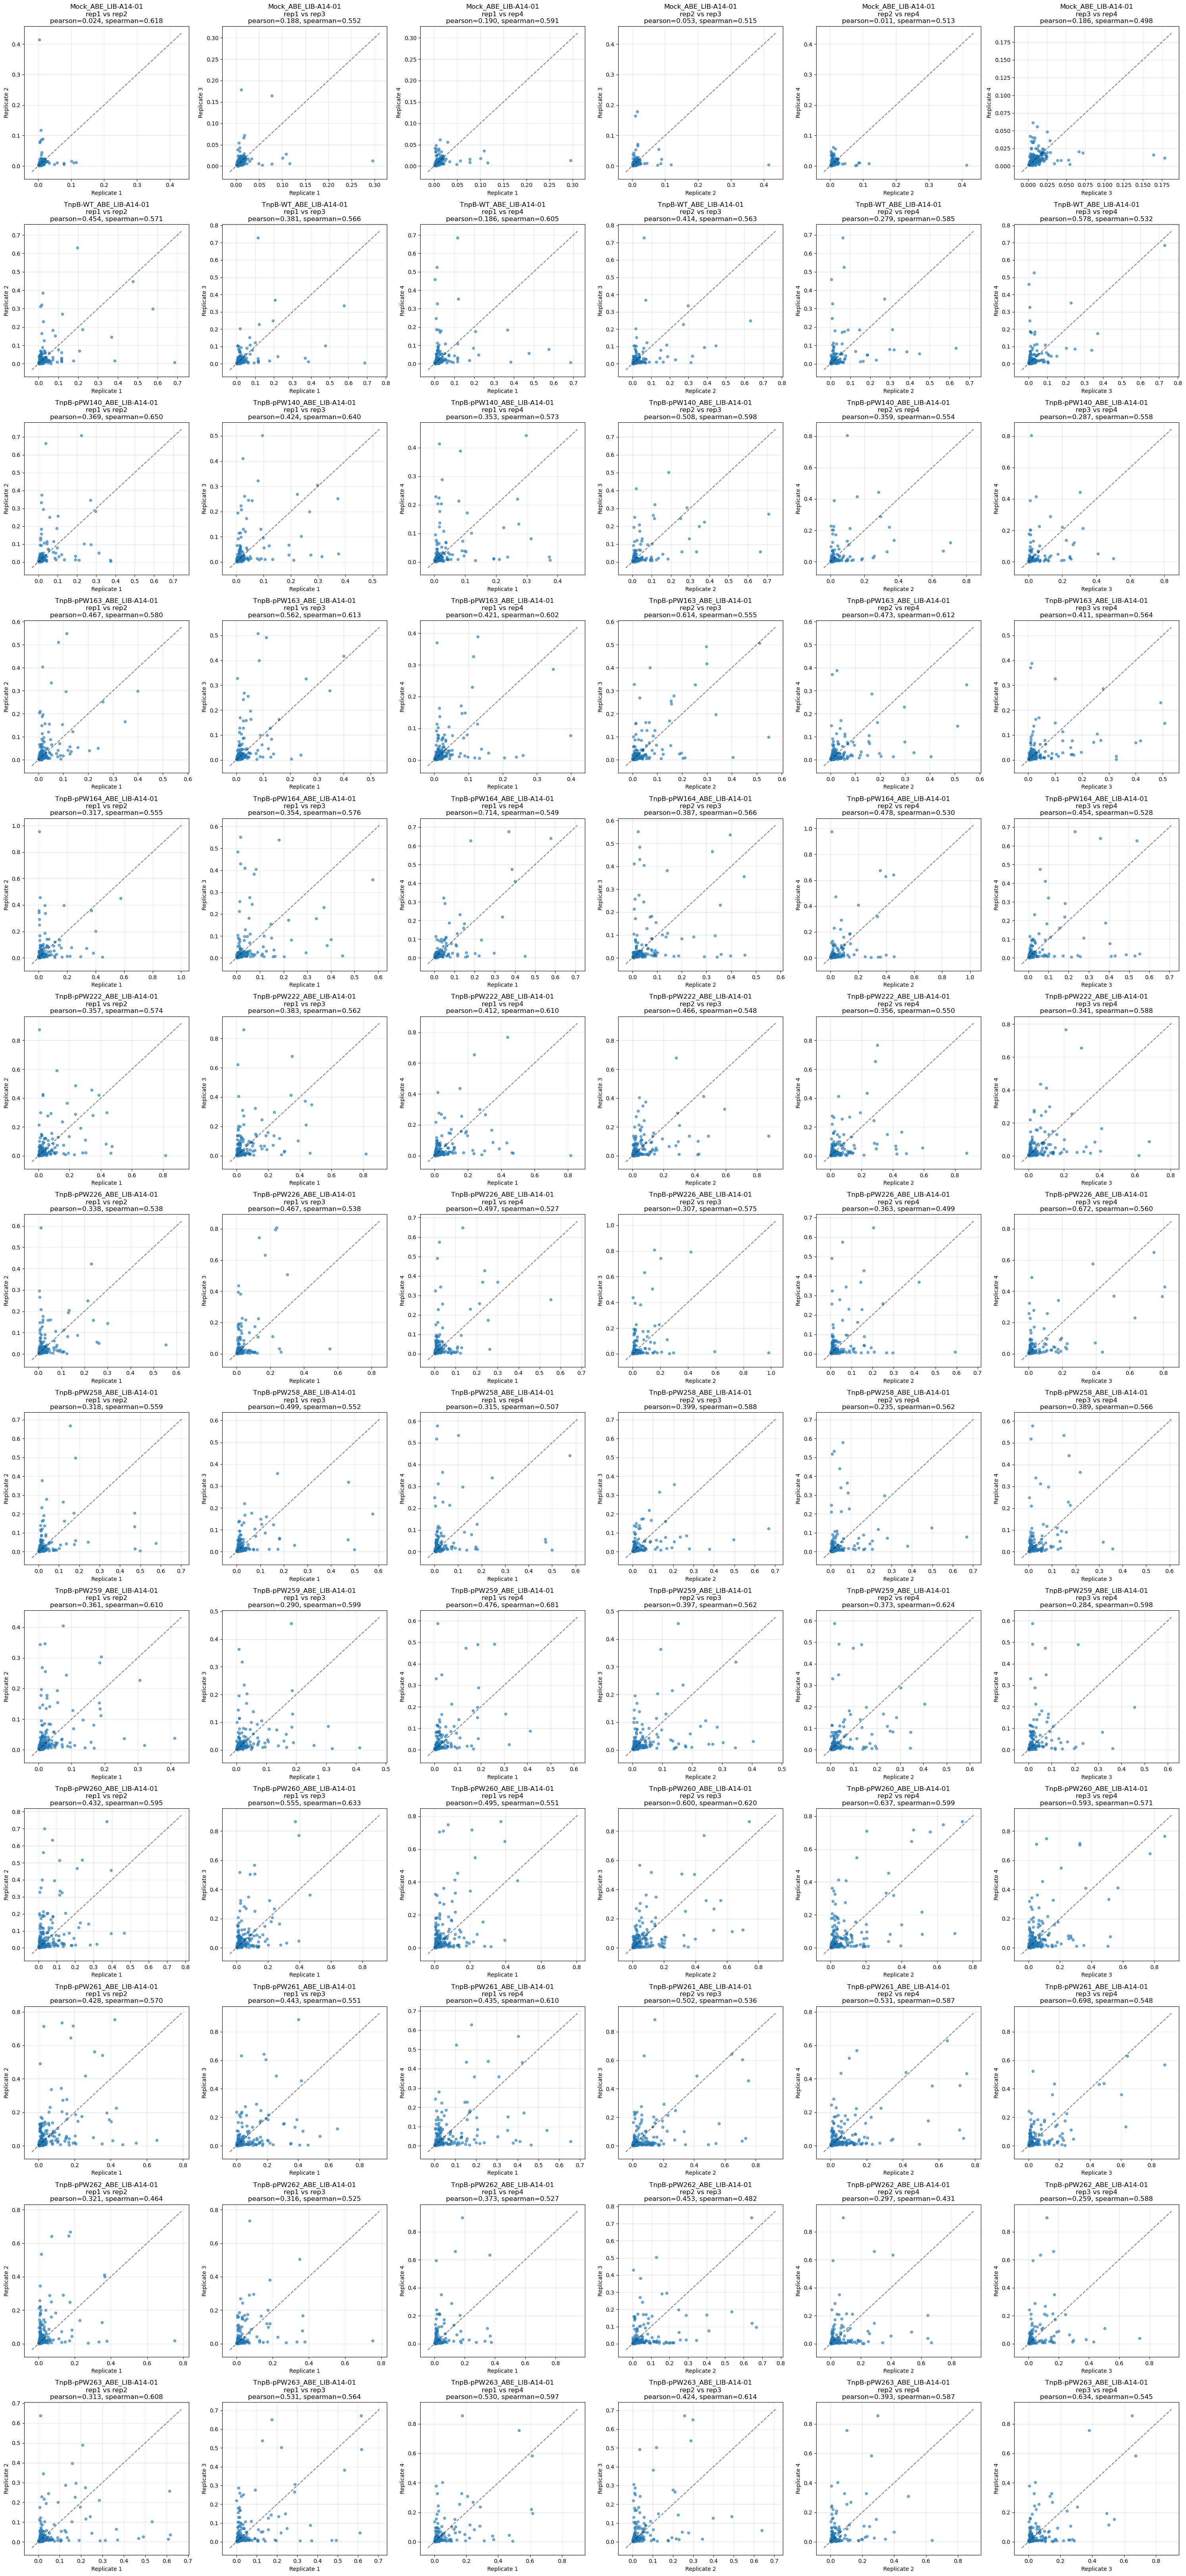

In [16]:
from scipy.stats import pearsonr, spearmanr

import matplotlib.pyplot as plt

def plot_paired_correlations(df,corr_edit_thres=0.3):
    """df have edit rate for different editor in different replicate, each column is one replice .
    column name are like this "frac_reads_edited_Mock_130_ABE_LIB-130_d10_rep1", "frac_reads_edited_Mock_130_ABE_LIB-130_d10_rep1"
    now i want to draw scatter plot between different replicates, for each editor, the plot in in row
    and show pearsonand spearman correlation in the figure legened

    for corr_edit_thres, only plot the replicates pair with correlation higher than this thres
    since editors have no/low editing for most of pams

    """
    # Extract editor names from column names
    editors = {}
    for col in df.columns:
        if col.startswith('frac_reads_edited_'):
            # Extract editor name (everything between 'frac_reads_edited_' and the last '_rep')
            editor_part = col.replace('frac_reads_edited_', '')
            editor_name = '_'.join(editor_part.split('_')[:-1])  # Remove the last _repX part
            if editor_name not in editors:
                editors[editor_name] = []
            editors[editor_name].append(col)

    # Create subplots - each row for one editor, columns for pairwise comparisons
    n_editors = len(editors)
    max_pairs = max(len(cols) * (len(cols) - 1) // 2 for cols in editors.values() if len(cols) > 1)

    fig, axes = plt.subplots(n_editors, max_pairs, figsize=(5*max_pairs, 5*n_editors))
    if n_editors == 1:
        axes = axes.reshape(1, -1)
    elif max_pairs == 1:
        axes = axes.reshape(-1, 1)

    for row_idx, (editor, columns) in enumerate(editors.items()):
        if len(columns) < 2:
            continue

        # Get all pairs of replicates
        pair_idx = 0
        for i in range(len(columns)):
            for j in range(i+1, len(columns)):
                col1, col2 = columns[i], columns[j]

                # Get data for correlation (remove NaN values)
                mask = ~(df[col1].isna() | df[col2].isna())
                x_data = df[col1][mask]
                y_data = df[col2][mask]

                #for x_data and y data. filter to get ones that both x_data and y_data > corr_edit_thres
                mask_corr_thres = (x_data > corr_edit_thres) & (y_data > corr_edit_thres) # (x_data > corr_edit_thres) | (y_data > corr_edit_thres)
                x_data = x_data[mask_corr_thres]
                y_data = y_data[mask_corr_thres]

                if len(x_data) > 0:
                    # Calculate correlations
                    pearson_r, pearson_p = pearsonr(x_data, y_data)
                    spearman_r, spearman_p = spearmanr(x_data, y_data)

                    # Plot scatter
                    ax = axes[row_idx, pair_idx]
                    ax.scatter(x_data, y_data, alpha=0.6, s=20)

                    # Extract replicate numbers
                    rep1 = col1.split('_rep')[-1]
                    rep2 = col2.split('_rep')[-1]

                    ax.set_xlabel(f'Replicate {rep1}')
                    ax.set_ylabel(f'Replicate {rep2}')
                    ax.set_title(f'{editor}\nrep{rep1} vs rep{rep2}\npearson={pearson_r:.3f}, spearman={spearman_r:.3f}')
                    ax.grid(True, alpha=0.3)

                    # Add diagonal line
                    max_val = max(ax.get_xlim()[1], ax.get_ylim()[1])
                    min_val = min(ax.get_xlim()[0], ax.get_ylim()[0])
                    ax.plot([min_val, max_val], [min_val, max_val], 'k--', alpha=0.5)

                    pair_idx += 1

        # Hide unused subplots in this row
        for col_idx in range(pair_idx, max_pairs):
            axes[row_idx, col_idx].set_visible(False)

    plt.tight_layout()
    plt.show()

plot_paired_correlations(all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim,
                         corr_edit_thres=0.)

# here is correlatoin plot is meaningless, since most TAMs have low editing 

In [17]:
NAS_folder = "/mnt/G_Pharma/Users/tfang/Cell_Screen/PW_A14-02_Screen/output_transfered"
os.makedirs(NAS_folder, exist_ok=True)

def plot_heatmap_for_bioreplicate(mean_fracs, bioreplicate, vis_edit_thres=0.1, figsize=(8,6), cmap="viridis", save_figure=True, prefix="notNormalized"):

    # Filter for the specified bioreplicate and compute heatmap data
    df_heat = mean_fracs[mean_fracs["bioreplicate"] == bioreplicate].copy()
    df_heat.loc[df_heat['frac_reads_edited'] < vis_edit_thres, 'frac_reads_edited'] = 0
    # Check if all PAMs from config.PAMS are present in df_heat["TAM"]
    missing_pams = set(config.PAMS) - set(df_heat["TAM"].unique())
    if missing_pams:
        # For each missing PAM, add a row with frac_reads_edited set to 0
        df_missing = pd.DataFrame({'TAM': list(missing_pams), 'frac_reads_edited': 0})
        df_heat = pd.concat([df_heat, df_missing], ignore_index=True)
    df_heat["TAM_row"] = df_heat["TAM"].str[:2]
    df_heat["TAM_col"] = df_heat["TAM"].str[-3:]
    pivot_heat = df_heat.pivot_table(index="TAM_row",
                                     columns="TAM_col",
                                     values="frac_reads_edited",
                                     aggfunc="mean").fillna(0)

    # Plot the heatmap
    pivot_heat = pivot_heat.sort_index(key=lambda x: [s[1] + s[0] for s in x], ascending=True)

    plt.figure(figsize=figsize)
    sns.heatmap(pivot_heat, fmt=".3f", cmap=cmap, vmin=0, vmax=1)
    plt.yticks(rotation=0)
    plt.title(f"Heatmap of frac_reads_edited for {bioreplicate}")
    plt.ylabel("First two letters of TAM")
    plt.xlabel("Last three letters of TAM")
    plt.tight_layout()

    #Save the figure to NAS_folder
    if save_figure:
        save_path = os.path.join(NAS_folder, f"{prefix}_heatmap_{bioreplicate}_{vis_edit_thres}.png")
        plt.savefig(save_path)
        plt.show()

mean_fracs_not_normalized = all_abe_samples_reads_editedrates_not_normalized.groupby(['bioreplicate','TAM', 'spacer'])['frac_reads_edited'].mean().reset_index()
mean_fracs_not_normalized.sort_values(by=['bioreplicate','spacer'], inplace=True)
mean_fracs_not_normalized.head(n=30)

,bioreplicate,TAM,spacer,frac_reads_edited
0,Mock_ABE_LIB-A14-01,AAGAT,AAGGAGATTATACCCAGAAT,0.008094
20,Mock_ABE_LIB-A14-01,ACGAT,AAGGAGATTATACCCAGAAT,0.007292
39,Mock_ABE_LIB-A14-01,AGGAT,AAGGAGATTATACCCAGAAT,0.007676
60,Mock_ABE_LIB-A14-01,ATGAT,AAGGAGATTATACCCAGAAT,0.007451
79,Mock_ABE_LIB-A14-01,CAGAT,AAGGAGATTATACCCAGAAT,0.024074
100,Mock_ABE_LIB-A14-01,CCGAT,AAGGAGATTATACCCAGAAT,0.008173
121,Mock_ABE_LIB-A14-01,CGGAT,AAGGAGATTATACCCAGAAT,0.005917
142,Mock_ABE_LIB-A14-01,CTGAT,AAGGAGATTATACCCAGAAT,0.009186
162,Mock_ABE_LIB-A14-01,GAGAT,AAGGAGATTATACCCAGAAT,0.007658
182,Mock_ABE_LIB-A14-01,GCGAT,AAGGAGATTATACCCAGAAT,0.009492


In [18]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

In [19]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

all_abe_samples_reads_editedrates,_=normalize_editing_rate_reads(all_abe_samples_reads_editedrates_not_normalized,
        col_normalize_over=['spacer','TAM',"lib_section"],
        col_rate='frac_reads_edited',
        col_control='is_ctrl',
        th_ctrl_missing=1, #
        ctrl_edit_rate_thres=0.2, # 0.3
        ignore_control=['spacer', 'TAM',"lib_section"],
    )

print(all_abe_samples_reads_editedrates.shape)
all_abe_samples_reads_editedrates.head(n=3)

frac_low_num_read_in_control: 0.0. Drop these records
frac_unintendededit_in_control: 0.0011841326228537595. Drop these records
34 out of 477 sites are missing control editing rate. drop these sites
(19766, 15)


,barcode,spacer,TAM,frac_reads_edited,num_reads,target_site,target_site_lib,edit_positions,editor,sample_name,is_ctrl,replicate,bioreplicate,lib_section,spacer_LIB
0,AAAAATA,TTCTTTGAGACTTGGCATGC,GGGAT,0.0000,506,CTCTTTGAGACTTGGCATGC,TTCTTTGAGACTTGGCATGC,"[8, 10, 17]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-A14-01_rep1,False,1,TnpB-WT_ABE_LIB-A14-01,LIB-A14-01,TTCTTTGAGACTTGGCATGC
1,AAAACAG,TTAAAGAAAAATTCCTTGCC,TTAAT,0.0059,511,TCAAAGAAAAATTCCTTGCC,TTAAAGAAAAATTCCTTGCC,"[3, 4, 5, 7, 8, 9, 10, 11]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-A14-01_rep1,False,1,TnpB-WT_ABE_LIB-A14-01,LIB-A14-01,TTAAAGAAAAATTCCTTGCC
2,AAAAGGC,CTAAGAAGTTATACTCTTTC,TAGAT,0.0000,5893,ATAAGAAGTTATACTCTTTC,CTAAGAAGTTATACTCTTTC,"[3, 4, 6, 7, 11, 13]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-A14-01_rep1,False,1,TnpB-WT_ABE_LIB-A14-01,LIB-A14-01,CTAAGAAGTTATACTCTTTC


In [20]:
save_path=NAS_folder
all_abe_samples_reads_editedrates_not_normalized.to_csv(os.path.join(save_path,'all_abe_samples_reads_editedrates_not_normalized.csv'))
print(os.path.join(save_path,'all_abe_samples_reads_editedrates_not_normalized.csv'))

all_abe_samples_reads_editedrates.to_csv(os.path.join(save_path,'all_abe_samples_reads_editedrates_normalized.csv'))
print(os.path.join(save_path,'all_abe_samples_reads_editedrates_normalized.csv'))

/mnt/G_Pharma/Users/tfang/Cell_Screen/PW_A14-02_Screen/output_transfered/all_abe_samples_reads_editedrates_not_normalized.csv
/mnt/G_Pharma/Users/tfang/Cell_Screen/PW_A14-02_Screen/output_transfered/all_abe_samples_reads_editedrates_normalized.csv
